# TraceLLM — 3 exercícios de geração (inferência, sem treino)

Este notebook roda os **checkpoints reais** do paper *"Large Language Models as
Realistic Microservice Trace Generators"* (TraceLLM, EMNLP 2025,
[aclanthology.org/2025.emnlp-main.4](https://aclanthology.org/2025.emnlp-main.4.pdf))
e do repositório oficial [`ldos-project/TraceLLM`](https://github.com/ldos-project/TraceLLM).

**O que fazemos aqui: só inferência.** Carregamos o Llama-2-7B e aplicamos por
cima os adapters LoRA publicados pelos autores (~8 MB cada, já prontos no repo,
`checkpoints/llama-2-7b/{baseline,recursive,recursive+instruction}`). Nenhum
gradiente é calculado, nenhum peso novo é treinado.

**Os 3 formatos:**
- `baseline` → formato tabular (estilo GReaT, grafo inteiro numa resposta só).
- `recursive` → formato recursivo em camadas (§3.1.2), sem instruction tuning.
- `recursive+instruction` → recursivo + instruction tuning com instruções
  intermediárias ("scratchpad" de aritmética, §3.2.1, Figura 11 do paper).

**Como os exercícios se relacionam com o paper:**
| Exercício | Figura do paper | Pergunta |
|---|---|---|
| 1 | Fig. 3a / 3b (e Fig. 12) | A recursão e as instruções intermediárias mantém a accuracy conforme o grafo fica maior/mais profundo? |
| 2 | Fig. 3c | Essa vantagem se mantém com diferentes temperaturas (temperatura > 0)? |
| 3 | Fig. 6 | O modelo obedece instruções novas, que não foi treinado? |

## Setup — clonar o repo e instalar dependências

Clonamos o repo oficial (ele já traz os 3 checkpoints LoRA e os prompts reais
de avaliação em `trace_gen/sft_heatmap_prompts*/`, ~200 MB no total.

In [2]:
# Clona o repo oficial num diretorio temporario (fora deste notebook) e instala as
# dependencias dele. As celulas seguintes usam caminhos relativos (trace_gen/...,
# checkpoints/...), por isso o cwd do kernel precisa ficar na raiz do repo clonado.
import os
import subprocess
import tempfile

REPO_URL = "https://github.com/ldos-project/TraceLLM.git"
REPO_DIR = os.path.join(tempfile.gettempdir(), "TraceLLM_repo")

if not os.path.isdir(os.path.join(REPO_DIR, "trace_gen")):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)

os.chdir(REPO_DIR)
print("Repo em:", os.getcwd())

# Mesmos pacotes do trace_gen/requirements.txt do repo (menos vllm/trl, so
# necessarios para treino/serving) + matplotlib/seaborn para os graficos.
%pip install -q torch huggingface_hub accelerate datasets httpx numpy packaging \
    pandas parse peft pydantic transformers bitsandbytes matplotlib seaborn

Repo em: C:\Users\PAULOO~1\AppData\Local\Temp\TraceLLM_repo
Note: you may need to restart the kernel to use updated packages.


## Login no Hugging Face

Precisa ter aceitado a licença do Llama-2 em
`huggingface.co/meta-llama/Llama-2-7b-hf` com a conta cujo token vocês vão usar.

In [3]:
from huggingface_hub import login
login(token="")  # cole seu token quando for solicitado

## Carregando o modelo base em 4-bit + os 3 adapters LoRA

- O paper usa Llama-2 7B + LoRA com `rank=8, alpha=16, dropout=0.1` nas
  projeções de atenção (Apêndice B.1; confirmado nos `adapter_config.json` de
  cada checkpoint do repo).
- Carregamos em **4-bit (`bitsandbytes`, NF4)** — ~4-5 GB de pesos, sobrando
  memória de GPU para gerar em lote.
- Carregamos os 3 adapters de uma vez com `peft` e trocamos entre eles com
  `set_adapter(...)` — troca instantânea, sem reler nada do disco.

In [4]:
# Silencia avisos que nao afetam os resultados (deixam a saida das celulas ilegivel):
# - "triton not found": o PyTorch no Windows nao tem triton; nao usamos.
# - SyntaxWarning '\d': regex sem prefixo r"" no codigo do repo (trace_gen/schema/api_call.py).
# - "custom validator is returning a value other than self": validador pydantic do repo
#   (CallGraph) - ele altera o proprio objeto, entao o resultado da validacao nao muda.
# - "Both max_new_tokens and max_length": o generation_config do Llama-2 traz max_length=4096.
import logging, warnings
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=SyntaxWarning)
warnings.filterwarnings("ignore", message="A custom validator is returning a value other than `self`")

In [5]:
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

transformers.logging.set_verbosity_error()

BASE_MODEL_ID = "meta-llama/Llama-2-7b-hf"
CKPT_DIR = "checkpoints/llama-2-7b"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,  # RTX 5070 (Blackwell) tem bf16 nativo
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token
# padding_side="left" e essencial para geracao em lote com modelo decoder-only
tokenizer.padding_side = "left"

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
)
# o generation_config do Llama-2 fixa max_length=4096; usamos so max_new_tokens
base_model.generation_config.max_length = None

model = PeftModel.from_pretrained(base_model, f"{CKPT_DIR}/baseline", adapter_name="baseline")
model.load_adapter(f"{CKPT_DIR}/recursive", adapter_name="recursive")
model.load_adapter(f"{CKPT_DIR}/recursive+instruction", adapter_name="recursive_instruction")
model.eval()
print("Adapters carregados:", list(model.peft_config.keys()))

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Adapters carregados: ['baseline', 'recursive', 'recursive_instruction']


## Importando o código oficial de parsing/validação do repo

Não vamos reimplementar o parser do formato de edges nem o checador de DAG —
isso já existe e é usado pelos próprios autores para medir *accuracy* no paper:
- `trace_gen/generate/trace_oracle/schema/validator.py` (`GenOutputValidator`)
- `trace_gen/generate/trace_oracle/schema/gen_request.py` (`GenRequest`,
  decide quando a recursão continua ou para)
- `trace_gen/generate/trace_oracle/schema/task_type.py` (`TraceGenTaskType`,
  `GraphGenInstruction`)
- `trace_gen/schema/call_graph.py` / `api_call_trie.py` (checagem de DAG válido)

A única coisa do repo que **não** importamos é `generator.py` — ele faz a
geração via HTTP para um servidor vLLM, e aqui vamos gerar localmente com
`transformers`. Reimplementamos só essa parte (próxima seção), mantendo a
mesma lógica de recursão.

In [6]:
import sys
sys.path.append(".")

from trace_gen.generate.trace_oracle.schema.validator import GenOutputValidator
from trace_gen.generate.trace_oracle.schema.gen_request import GenRequest
from trace_gen.generate.trace_oracle.schema.task_type import TraceGenTaskType, GraphGenInstruction
from trace_gen.schema.call_graph import CallGraph
from trace_gen.utils.preprocessing.read_file import file_to_samples

validator = GenOutputValidator()
print("OK - validador oficial do repo importado.")

OK - validador oficial do repo importado.


## Geração em lote + recursão (substituindo o vLLM por `transformers`)

Três peças, propositalmente separadas:

**1) `generate_batch`** — faz UMA chamada de inferência para várias prompts de
uma vez (`model.generate` com padding). Imita o batching que `generator.py` do
repo faz via HTTP para o vLLM — a diferença é só o transporte. Se a GPU ficar
sem memória, o lote é dividido ao meio e refeito.

*Limite de tokens por camada.* O limite de
cada lote é **proporcional ao tamanho pedido** (`num_current_edges`,
`num_subgraphs`, `num_edges`), calibrado nos dados de treino de exemplo do repo
com folga — uma saída correta sempre cabe; uma saída maior que isso já estaria
errada de qualquer forma. A fila também é ordenada por esse tamanho, para lotes
com camadas parecidas.

**2) `run_recursive_generation`** — o laço que decide se a recursão continua.
Ele **não reimplementa a lógica de decisão** — chama direto
`GenRequest.make_child_requests` (`gen_request.py`), que lê os blocos
`<subgraph of edge_id N>` da resposta do modelo e cria as próximas chamadas.
Se não aparecer nenhum bloco, aquele ramo da árvore para.

*Camadas `<split>`.* Quando uma camada precisa de mais de 15 edges, o modelo
primeiro a divide em pedaços menores (`<split>`) e só depois gera as edges de
cada pedaço. O prompt padrão que `gen_request.py` monta para essas camadas
tem um formato levemente diferente do usado no treino; `ajusta_prompt_split`
corrige isso para bater exatamente com o formato de treino (`sft.py`): linha
em branco antes de ` ### Answer:` no formato com instrução, e a tag
`<split>` no fim do prompt no formato recursivo.

**3) `run_grid`** — sorteia prompts reais para várias combinações
(`num_edges`, `depth`), gera todas numa fila só e devolve uma tabela com o
acerto de cada grafo. Opcionalmente salva **o texto gerado em cada camada**
(arquivo `.jsonl`), para inspecionar erros sem precisar gerar de novo.

In [7]:
import os, json, random, time
from collections import deque
import pandas as pd

STOP_STRINGS = {
    "non_recursive": ["##", "finish generation", "</edges>"],
    "recursive": ["##", "finish generation", "[GENERATE", "</layer>", "</split>"],
    "recursive_instruction": ["##", "finish generation", "</layer>", "</split>"],
}
ADAPTER_OF_GEN_TYPE = {
    "non_recursive": ["baseline"],
    "recursive": ["recursive"],
    # O adapter de instrucao foi treinado EM CIMA do adapter "recursive" (que faz
    # o papel do pre-treino em traces); por isso os dois precisam estar ativos
    # juntos (soma dos deltas LoRA = merge) para a saida seguir o formato esperado.
    "recursive_instruction": ["recursive", "recursive_instruction"],
}
TASK_TYPE_OF_GEN_TYPE = {
    "non_recursive": TraceGenTaskType.graph_gen_non_recursive,
    "recursive": TraceGenTaskType.graph_gen_recursive,
    "recursive_instruction": TraceGenTaskType.graph_gen,
}

# Limite de tokens por camada: proporcional ao que foi pedido. Coeficientes medidos
# nas saidas de dataset_examples/ (tokens por edge / por subgrafo), com folga.
TOKENS_MAX = {'non_recursive': 2048, 'recursive': 2048, 'recursive_instruction': 3584}
TOKENS_POR_EDGE = {'non_recursive': 65, 'recursive': 55, 'recursive_instruction': 50}
TOKENS_POR_SUBGRAFO = {'non_recursive': 0, 'recursive': 110, 'recursive_instruction': 200}
TOKENS_FOLGA = {'non_recursive': 80, 'recursive': 80, 'recursive_instruction': 150}
EDGE_THRESHOLD = 15  # camadas com mais edges que isso viram <split> (gen_request.py)

# Teto de tokens por lote (prompt + geracao, somado em todas as sequencias), calibrado
# para esta GPU (12 GB) com o modelo em 4-bit e cache estatico: o consumo de memoria e
# proporcional ao total de tokens do lote, e 4500 tokens deixa folga para o desktop e
# outros programas que tambem usam a GPU. Um teto maior arrisca estourar a memoria (ou,
# no Windows, transbordar para a RAM do sistema e ficar muito lento).
TOKENS_POR_LOTE = 4500


def _atributos(prompt, gen_type):
    # le a linha de requisitos da camada (ex.: "num_edges:5/num_current_edges:1/...")
    if gen_type == "recursive_instruction":
        linha = prompt.split("Requirements:", 1)[1].strip().split("\n", 1)[0]
    else:
        linha = prompt.strip().split("\n", 1)[0].replace("[GENERATE GRAPH]", "")
    return dict(kv.split(":", 1) for kv in linha.split("/") if kv.count(":") == 1)


def orcamento_tokens(prompt, gen_type):
    try:
        a = _atributos(prompt, gen_type)
        if gen_type == "non_recursive":
            n = int(a.get("num_edges", -1))
            s = 0
        else:
            n = int(a.get("num_current_edges", -1))
            s = int(a.get("num_subgraphs", n))
            if n > EDGE_THRESHOLD:  # camada de <split>: so linhas de subgrafo
                n, s = 0, n // EDGE_THRESHOLD + 2
        if n < 0 or s < 0:
            return TOKENS_MAX[gen_type]
        estimativa = (TOKENS_POR_EDGE[gen_type] * n + TOKENS_POR_SUBGRAFO[gen_type] * s
                      + TOKENS_FOLGA[gen_type])
        return int(min(TOKENS_MAX[gen_type], estimativa))
    except Exception:
        return TOKENS_MAX[gen_type]


def _truncate_at_stop(text, stops):
    cut = len(text)
    for s in stops:
        idx = text.find(s)
        if idx != -1:
            cut = min(cut, idx + len(s))
    return text[:cut]


def _generate(prompts, gen_type, temperature, max_new_tokens):
    inputs = tokenizer(prompts, return_tensors="pt", padding=True,
                       truncation=True, max_length=1024).to(model.device)
    gen_kwargs = dict(
        max_new_tokens=max_new_tokens,
        do_sample=temperature > 0.0,
        pad_token_id=tokenizer.pad_token_id,
        stop_strings=STOP_STRINGS[gen_type],  # mesmas stop strings do repo
        tokenizer=tokenizer,
        # Cache estatico: reserva a memoria do cache de atencao uma vez so. O cache
        # padrao (dinamico) cresce token a token e fragmenta a memoria da GPU, usando
        # bem mais memoria do que o necessario para o tamanho real do lote.
        cache_implementation="static",
    )
    if temperature > 0.0:
        gen_kwargs.update(temperature=temperature, top_k=50)  # top_k=50 como no repo
    with torch.no_grad():
        out = model.generate(**inputs, **gen_kwargs)
    new_tokens = out[:, inputs["input_ids"].shape[1]:]
    texts = tokenizer.batch_decode(new_tokens, skip_special_tokens=False)
    del out, new_tokens, inputs
    # (sem empty_cache aqui: chamar isso em todo lote bem-sucedido so custa uma
    # sincronizacao+realocacao a mais a cada chamada; a limpeza por fragmentacao
    # so e necessaria quando falta memoria mesmo, e isso ja e tratado no except
    # de generate_batch, que chama empty_cache so antes de tentar de novo.)
    return [_truncate_at_stop(t, STOP_STRINGS[gen_type]) for t in texts]


def generate_batch(prompts, gen_type, temperature=0.0):
    # Uma unica chamada batched de generate() para varias prompts.
    model.base_model.set_adapter(ADAPTER_OF_GEN_TYPE[gen_type])
    max_new_tokens = max(orcamento_tokens(p, gen_type) for p in prompts)
    try:
        return _generate(prompts, gen_type, temperature, max_new_tokens)
    except RuntimeError as e:  # OutOfMemoryError ou AcceleratorError("CUDA error: out of memory")
        if "out of memory" not in str(e).lower() or len(prompts) == 1:
            raise
    # sem memoria de GPU: divide o lote ao meio e tenta de novo
    torch.cuda.empty_cache()
    mid = len(prompts) // 2
    return (generate_batch(prompts[:mid], gen_type, temperature)
            + generate_batch(prompts[mid:], gen_type, temperature))


def run_recursive_generation(root_requests, gen_type, temperature=0.0,
                             batch_size=16, verbose=False):
    # Espelha TraceGenerator.start_generation (generator.py), troca so o
    # transporte (HTTP->vLLM vira generate_batch local).
    queue = deque(root_requests)
    n_calls, t0 = 0, time.time()
    while queue:
        # lotes com camadas de tamanho parecido (menos espera pela sequencia mais longa)
        queue = deque(sorted(queue, key=lambda r: orcamento_tokens(r.prompt, gen_type)))
        batch = []
        # enche o lote ate batch_size prompts ou ate o teto de tokens (o que vier antes)
        while queue and len(batch) < batch_size:
            candidato = batch + [queue[0]]
            maior = max(len(r.prompt) // 3 + orcamento_tokens(r.prompt, gen_type) for r in candidato)
            if batch and len(candidato) * maior > TOKENS_POR_LOTE:
                break
            batch.append(queue.popleft())
        texts = generate_batch([r.prompt for r in batch], gen_type, temperature=temperature)
        n_calls += len(batch)
        for request, text in zip(batch, texts):
            request.trials.append(text)
            try:
                request.check_validity(validator)
            except Exception:
                request.is_valid = False
            if request.is_valid:
                try:
                    # so gera filhos se houver bloco <subgraph of edge_id N> na resposta.
                    # Para o formato non_recursive nao faz nada (sem recursao).
                    request.make_child_requests(
                        validator,
                        include_description=(request.task_type == TraceGenTaskType.graph_gen),
                    )
                except Exception:
                    pass
                for child in request.child_requests:
                    ajusta_prompt_split(child, gen_type)
                    queue.append(child)
        if verbose:
            print(f"\r  {n_calls} chamadas ao modelo, {len(queue)} na fila, "
                  f"{time.time() - t0:.0f}s", end="", flush=True)
    if verbose:
        print()
    return root_requests


def ajusta_prompt_split(child, gen_type):
    # Camadas com mais de 15 edges viram <split> (a camada e dividida em pedacos antes
    # de gerar as edges). O prompt padrao que gen_request.py monta para elas tem um
    # formato levemente diferente do usado no treino; os ajustes abaixo corrigem isso
    # para bater com o formato de treino (sft.py):
    # - recursive_instruction: precisa de uma linha em branco antes de " ### Answer:",
    #   igual no treino, para o modelo escrever "Subgraph constraints:" e fechar
    #   corretamente a soma dos pedacos.
    # - recursive: o prompt do filho precisa terminar com "<split>\n" (como o formato
    #   com instrucao ja faz), para o modelo abrir o bloco de split em vez de tentar
    #   gerar as edges direto.
    if gen_type == "recursive_instruction":
        fim = "\n ### Answer: \n<split>\n"
        if child.prompt.endswith(fim) and not child.prompt.endswith("\n" + fim):
            child.prompt = child.prompt[: -len(fim)] + "\n" + fim
    elif gen_type == "recursive":
        n = int(_atributos(child.prompt, gen_type).get("num_current_edges", -1))
        if n > EDGE_THRESHOLD and not child.prompt.endswith("<split>\n"):
            child.prompt += "<split>\n"


def is_accurate(root_request, expected_num_edges, expected_depth):
    # Replica a metrica "accuracy" do paper (§4.1): o grafo final bate o
    # num_edges e o depth pedidos E passa as checagens estruturais de DAG.
    try:
        if not root_request.is_finished:
            return False
        if root_request.task_type == TraceGenTaskType.graph_gen_non_recursive:
            _, cg = validator.parse(root_request.task_type,
                                    root_request.prompt + root_request.trials[-1])
            depth_target = expected_depth
        else:
            edges = root_request.collected_generated_edges()
            cg = CallGraph(service_id=0, edges=edges)
            # +1: "depth" na instrucao dos recursivos e remaining_depth do ROOT;
            # profundidade total = remaining_depth + 1 (ver generator.py).
            depth_target = expected_depth + 1
        if not cg.valid:
            return False
        if expected_num_edges > 0 and len(cg.edges) != expected_num_edges:
            return False
        if depth_target >= 0 and cg.edge_dag.root.depth != depth_target:
            return False
        return True
    except Exception:
        return False


def arvore(request):
    # texto gerado em cada camada (para salvar em .jsonl e inspecionar erros)
    motivos = request.invalid_reasons[-1] if request.invalid_reasons else []
    return {
        "prompt": request.prompt,
        "saida": request.trials[-1] if request.trials else None,
        "valida": request.is_valid,
        "motivos_invalida": [getattr(m, "detail", str(m)) for m in motivos],
        "filhos": [arvore(c) for c in request.child_requests],
    }


def load_prompt_blocks(num_edges, depth, gen_type):
    prompt_dir = {
        "non_recursive": "sft_heatmap_prompts_baseline",
        "recursive": "sft_heatmap_prompts_recursive",
        "recursive_instruction": "sft_heatmap_prompts",
    }[gen_type]
    path = f"trace_gen/{prompt_dir}/{num_edges}_{depth}.txt"
    return file_to_samples(path, lambda x: "### Question:" in x)


def extract_requirement_line(block, gen_type):
    # Extrai a linha de atributos (Requirements) de um exemplo real.
    text = block
    if gen_type == "recursive_instruction" and "Requirements:" in text:
        return text.split("Requirements:", 1)[1].strip().split("\n", 1)[0]
    if "### Question:" in text:
        text = text.split("### Question:", 1)[1]
    return text.strip().split("\n", 1)[0]


def build_root_requests(blocks, gen_type, n=3):
    # Monta as prompts exatamente como run_validation_heatmap.py do repo.
    task_type = TASK_TYPE_OF_GEN_TYPE[gen_type]
    pairs = []
    for block in blocks[:n]:
        req_line = extract_requirement_line(block, gen_type)
        instr = GraphGenInstruction.from_prompt(req_line)
        if gen_type == "non_recursive":
            prompt = req_line + "\n<edges>\n"
        elif gen_type == "recursive":
            prompt = req_line + "\n<layer>\n<edges>\n"
        else:
            prompt = block + "\n ### Answer: \n<layer>\n<edges>"
        pairs.append((GenRequest(prompt=prompt, task_type=task_type, sampling_params={}), instr))
    return pairs


def run_grid(gen_type, cells, n_per_cell, temperature=0.0, seed=0, salvar_textos=None):
    # Sorteia n_per_cell prompts reais por (num_edges, depth), gera todas numa
    # fila so e devolve uma linha por grafo gerado (acerto = True/False).
    # salvar_textos: caminho .jsonl onde guardar o texto gerado em cada camada.
    rng = random.Random(seed)
    items = []
    for num_edges, depth in cells:
        blocks = load_prompt_blocks(num_edges, depth, gen_type)
        if not blocks:
            print(f"[aviso] sem prompts para {gen_type} (edges={num_edges}, depth={depth})")
            continue
        sample = rng.sample(blocks, min(n_per_cell, len(blocks)))
        for root, instr in build_root_requests(sample, gen_type, n=len(sample)):
            items.append((num_edges, depth, root, instr))
    print(f"{gen_type} (T={temperature}): {len(items)} grafos")
    t0 = time.time()
    run_recursive_generation([it[2] for it in items], gen_type, temperature, verbose=True)
    rows = []
    for e, d, root, instr in items:
        rows.append({"formato": gen_type, "temperatura": temperature, "num_edges": e, "depth": d,
                     "acerto": is_accurate(root, instr.num_edges, instr.depth)})
        if salvar_textos:
            with open(salvar_textos, "a", encoding="utf-8") as f:
                f.write(json.dumps({**rows[-1], "arvore": arvore(root)}, ensure_ascii=False) + "\n")
    df = pd.DataFrame(rows)
    print(f"  accuracy geral = {100 * df.acerto.mean():.1f}%  ({time.time() - t0:.0f}s)")
    return df


def limpa_arquivo(caminho):
    # recomeca o arquivo de textos a cada execucao da celula
    if os.path.exists(caminho):
        os.remove(caminho)
    return caminho


os.makedirs("resultados", exist_ok=True)
print("Funcoes de geracao/recursao definidas.")

Funcoes de geracao/recursao definidas.


## Teste rápido (sanity check)

Antes de rodar os 3 exercícios, geramos **1 exemplo só** e olhamos a saída crua
— só para confirmar que o pipeline (prompt real → modelo → parser do repo)
está funcionando antes de rodar os loops maiores.

In [8]:
blocks = load_prompt_blocks(num_edges=5, depth=2, gen_type="recursive_instruction")
print(f"{len(blocks)} prompts reais encontrados para (num_edges=5, depth=2)\n")

pairs = build_root_requests(blocks, "recursive_instruction", n=1)
roots = [p[0] for p in pairs]
run_recursive_generation(roots, "recursive_instruction", temperature=0.0)

root, instr = pairs[0]
print("--- Instrucao pedida ---")
print(instr)
print("\n--- Saida do modelo (1a camada) ---")
print(root.trials[-1][:800])
print("\nis_finished:", root.is_finished, "| is_valid:", root.is_valid)
print("accuracy:", is_accurate(root, instr.num_edges, instr.depth))

1814 prompts reais encontrados para (num_edges=5, depth=2)

--- Instrucao pedida ---
id='S_021853464' start_rpc_id='0' start_node='USER' num_edges=5 depth=1 latency=4 offset=0 num_subgraphs=1 num_current_edges=1

--- Saida do modelo (1a camada) ---

(communication finishes at 4 milliseconds,type is http,destination is MS_51288,edge_id is 0,communication starts at 0 milliseconds)
</edges>
num generated edges = the last edge id - the first edge id + 1 = 0 - 0 + 1 = 1
1 edges generated out of num_edges:5
num_remaining_edges = num_edges:5 - generated:1 = 4
copy start_node from edge 0 destination: MS_51288
<subgraph of edge_id 0>start_edge_id:1/num_current_edges:4/start_node:MS_51288/num_edges:4/caller:USER/remaining_depth:0/num_subgraphs:0/id:S_021853464/latency:4/start_communication_at:0</subgraph>
now, num_remaining_edges is 4 - 4 = 0
finish generation

is_finished: True | is_valid: True
accuracy: True


---
# Exercício 1 — Accuracy por nº de edges e por profundidade (Fig. 3a/3b)

**O que reproduz do paper:** Figura 3a/3b (§4.1) — accuracy dos **3 formatos**
(baseline tabular, recursivo, recursivo + instruções intermediárias) conforme o
grafo pedido fica maior (mais edges) e mais profundo. Mesmo protocolo do paper:
*greedy decoding*, prompts reais diferentes por combinação, e a métrica
*accuracy* de §4.1: o grafo gerado tem que bater o `num_edges` **e** o `depth`
pedidos **e** passar todas as checagens estruturais de DAG (Apêndice C).

Rodamos uma grade (`num_edges` × `depth`) uma única vez e tiramos os dois
gráficos dela: a Fig. 3a agrupa os resultados por `num_edges`, a Fig. 3b por
`depth`. A grade é reduzida em relação ao paper (que usa `num_edges` 1–30,
`depth` 1–6 e 50 amostras por combinação) para caber em tempo razoável.

In [ ]:
GRID_NUM_EDGES = [1, 3, 5, 10, 15, 20]
GRID_DEPTHS = [1, 2, 3, 4, 5]
N_PER_CELL = 10  # prompts reais diferentes por combinacao (greedy, 1 geracao cada)
FORMATOS = ["non_recursive", "recursive", "recursive_instruction"]

# mesma restricao usada em run_validation_heatmap.py (main())
cells_ex1 = [(e, d) for d in GRID_DEPTHS for e in GRID_NUM_EDGES
             if not (d > e or (e > 1 and d == 1))]
print(f"{len(cells_ex1)} combinacoes (num_edges, depth) x {N_PER_CELL} prompts x {len(FORMATOS)} formatos\n")

textos_ex1 = limpa_arquivo("resultados/ex1_textos.jsonl")
df_ex1 = pd.concat([run_grid(f, cells_ex1, N_PER_CELL, temperature=0.0, salvar_textos=textos_ex1)
                    for f in FORMATOS], ignore_index=True)
df_ex1.to_csv("resultados/ex1.csv", index=False)
df_ex1.pivot_table(index="formato", columns="depth", values="acerto", aggfunc="mean").mul(100).round(0)

19 combinacoes (num_edges, depth) x 10 prompts x 3 formatos

non_recursive (T=0.0): 190 grafos
  190 chamadas ao modelo, 0 na fila, 2286ss
  accuracy geral = 27.9%  (2286s)
recursive (T=0.0): 187 grafos
  568 chamadas ao modelo, 1 na fila, 8960sss

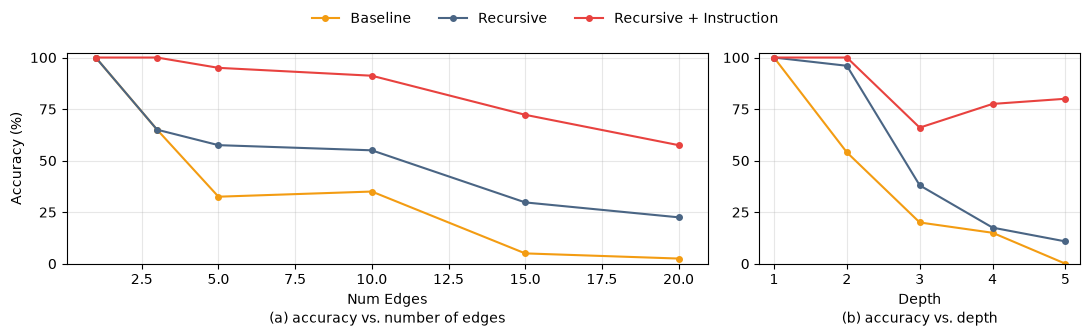

n por ponto (Fig. 3a): {1: 10, 3: 20, 5: 40, 10: 40, 15: 40, 20: 40}
n por ponto (Fig. 3b): {1: 10, 2: 50, 3: 50, 4: 40, 5: 40}


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# mesmas cores e nomes da Figura 3 do paper
COR = {"non_recursive": "#f39c12", "recursive": "#4a6584", "recursive_instruction": "#e8423f"}
NOME = {"non_recursive": "Baseline", "recursive": "Recursive",
        "recursive_instruction": "Recursive + Instruction"}


def linhas_por_formato(ax, df, coluna_x):
    for fmt in FORMATOS:
        s = df[df.formato == fmt].groupby(coluna_x)["acerto"].mean() * 100
        ax.plot(s.index, s.values, marker="o", markersize=4, linewidth=1.5,
                color=COR[fmt], label=NOME[fmt])
    ax.set_ylim(0, 102)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.grid(alpha=0.3)


fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
linhas_por_formato(ax_a, df_ex1, "num_edges")
ax_a.set_xlabel("Num Edges")
ax_a.set_ylabel("Accuracy (%)")
ax_a.set_title("(a) accuracy vs. number of edges", fontsize=10, y=-0.32)
linhas_por_formato(ax_b, df_ex1, "depth")
ax_b.set_xlabel("Depth")
ax_b.set_xticks(GRID_DEPTHS)
ax_b.set_title("(b) accuracy vs. depth", fontsize=10, y=-0.32)
handles, labels = ax_a.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

# quantos grafos entram em cada ponto (pontos com poucos grafos oscilam mais)
print("n por ponto (Fig. 3a):", df_ex1[df_ex1.formato == FORMATOS[0]].groupby("num_edges").size().to_dict())
print("n por ponto (Fig. 3b):", df_ex1[df_ex1.formato == FORMATOS[0]].groupby("depth").size().to_dict())

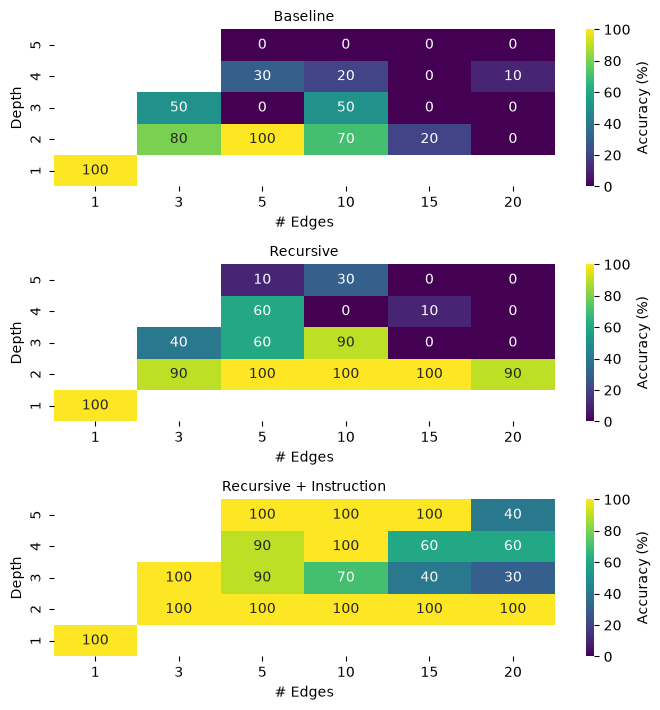

In [11]:
# Extra: a mesma grade em heatmap, um painel por formato (como a Figura 12 do apendice)
fig, axes = plt.subplots(len(FORMATOS), 1, figsize=(7, 2.4 * len(FORMATOS)))
for ax, fmt in zip(axes, FORMATOS):
    pivot = (df_ex1[df_ex1.formato == fmt]
             .pivot_table(index="depth", columns="num_edges", values="acerto", aggfunc="mean") * 100)
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".0f", cmap="viridis", vmin=0, vmax=100,
                cbar_kws={"label": "Accuracy (%)"})
    ax.invert_yaxis()
    ax.set_title(NOME[fmt], fontsize=10)
    ax.set_xlabel("# Edges")
    ax.set_ylabel("Depth")
fig.tight_layout()
plt.show()

### Perguntas — Exercício 1

**(a) Sobre o paper.** A geração do call graph é feita camada por camada — cada
camada usa só a condição resumida que chegou até ela, não o grafo inteiro. Por
que essa decomposição deveria facilitar o trabalho do modelo, comparado a gerar
o grafo inteiro de uma vez só?

> **Resposta:** 

**(b) Sobre o exercício.** Comparando as Figuras 3a (variando num_edges) e
3b (variando depth) nos seus resultados, qual dos dois — mais edges ou mais
profundidade — derruba mais a accuracy do baseline?

> **Resposta:**

---
# Exercício 2 — Accuracy vs. temperatura de amostragem (Fig. 3c)

**O que reproduz do paper:** a Figura 3c (§4.1) — accuracy dos 3 formatos numa
combinação fixa (`num_edges`, `depth`) variando a temperatura de amostragem. O
paper reporta que o formato recursivo mantém ~10% de vantagem sobre o baseline
mesmo em temperatura 1.0, e que as instruções intermediárias somam mais
23%–36%.

Usamos as **mesmas prompts** em todas as temperaturas (mesma semente de
sorteio), então a diferença entre os pontos de uma linha vem só da amostragem.

In [ ]:
EX2_NUM_EDGES, EX2_DEPTH = 10, 3
N_PER_TEMP = 20
TEMPERATURES = [0.0, 0.4, 0.8, 1.0]
FORMATOS = ["non_recursive", "recursive", "recursive_instruction"]

textos_ex2 = limpa_arquivo("resultados/ex2_textos.jsonl")
df_ex2 = pd.concat([run_grid(f, [(EX2_NUM_EDGES, EX2_DEPTH)], N_PER_TEMP, temperature=t,
                             salvar_textos=textos_ex2)
                    for f in FORMATOS for t in TEMPERATURES], ignore_index=True)
df_ex2.to_csv("resultados/ex2.csv", index=False)
df_ex2.pivot_table(index="formato", columns="temperatura", values="acerto", aggfunc="mean").mul(100).round(0)

non_recursive (T=0.0): 20 grafos
  20 chamadas ao modelo, 0 na fila, 553s
  accuracy geral = 70.0%  (553s)
non_recursive (T=0.4): 20 grafos
  20 chamadas ao modelo, 0 na fila, 558s
  accuracy geral = 35.0%  (558s)
non_recursive (T=1.0): 20 grafos
  20 chamadas ao modelo, 0 na fila, 534s
  accuracy geral = 35.0%  (534s)
recursive (T=0.0): 20 grafos
  51 chamadas ao modelo, 0 na fila, 691ss
  accuracy geral = 65.0%  (691s)
recursive (T=0.4): 20 grafos
  58 chamadas ao modelo, 0 na fila, 888ss
  accuracy geral = 70.0%  (888s)
recursive (T=0.8): 20 grafos
  57 chamadas ao modelo, 0 na fila, 1158s
  accuracy geral = 80.0%  (1158s)
recursive (T=1.0): 20 grafos
  52 chamadas ao modelo, 0 na fila, 881ss
  accuracy geral = 45.0%  (882s)
recursive_instruction (T=0.0): 20 grafos
  57 chamadas ao modelo, 0 na fila, 2082ss
  accuracy geral = 85.0%  (2082s)
recursive_instruction (T=0.4): 20 grafos
  55 chamadas ao modelo, 0 na fila, 1517s
  accuracy geral = 75.0%  (1517s)
recursive_instruction (T=0.

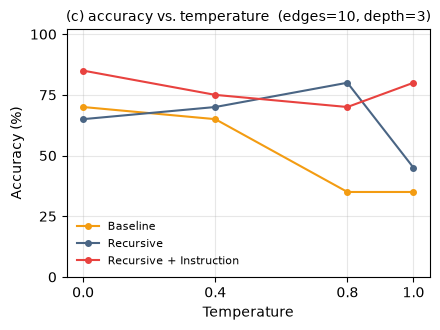

In [13]:
import matplotlib.pyplot as plt

# mesmas cores e nomes da Figura 3 do paper
COR = {"non_recursive": "#f39c12", "recursive": "#4a6584", "recursive_instruction": "#e8423f"}
NOME = {"non_recursive": "Baseline", "recursive": "Recursive",
        "recursive_instruction": "Recursive + Instruction"}

def linhas_por_formato(ax, df, coluna_x):
    for fmt in FORMATOS:
        s = df[df.formato == fmt].groupby(coluna_x)["acerto"].mean() * 100
        ax.plot(s.index, s.values, marker="o", markersize=4, linewidth=1.5,
                color=COR[fmt], label=NOME[fmt])
    ax.set_ylim(0, 102)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(4.5, 3.4))
linhas_por_formato(ax, df_ex2, "temperatura")
ax.set_xlabel("Temperature")
ax.set_ylabel("Accuracy (%)")
ax.set_xticks(TEMPERATURES)
ax.set_title(f"(c) accuracy vs. temperature  (edges={EX2_NUM_EDGES}, depth={EX2_DEPTH})", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

### Perguntas — Exercício 2

**(a) Sobre o paper.** O objetivo do TraceLLM é gerar datasets sintéticos
grandes e diversos (abstract: *"produces diverse, realistic traces under
varied conditions"*), e por isso os autores usam temperatura 0.8 na inferência
(Apêndice B.1), não greedy — que sempre gera a mesma saída pro mesmo prompt.
Mas a Figura 3c mostra que a accuracy cai conforme a temperatura sobe. Que
tradeoff isso revela sobre gerar traces sintéticos, e como os três formatos
lidam com ele de forma diferente?

> **Resposta:**

**(b) Sobre o exercício.** Comparando com a Figura 3c do paper, seus
resultados mostram o mesmo padrão geral — baseline mais baixo, recursive
acima do baseline, recursive + instruction acima dos dois? Descrevam o que
vocês observam.

> **Resposta:**

---
# Exercício 3 — Instruction-following: o modelo obedece instruções específicas? (Fig. 6)

**O que reproduz do paper:** a Seção 4.4 / Figura 6. No instruction tuning, os
autores incluíram dois tipos de instrução de atributo
(`trace_gen/schema/call_graph_layer.py`):
- **Comunicação rara** (*Uncommon comm.*): `Include an edge from (SRC) to (DEST)
  with (TYPE) type` — uma comunicação real que aparece em menos de 10% dos dados.
- **Latência alta** (*High lat.*): `Build a call graph with high latency` — o
  grafo deve ter latência acima do p90 daquele serviço. Nesses prompts o valor
  da latência **não** é informado: o modelo tem que decidir sozinho gerar algo alto.

Cada instrução isolada **foi vista no treino**; o que nunca foi visto é **as duas
juntas no mesmo prompt** (*Combined*). Esse é o teste de generalização: o modelo
consegue compor duas instruções que aprendeu separadamente?

### Como o experimento funciona

Os prompts de avaliação do repo já contêm essas instruções. Cada prompt é
gerado **duas vezes**:

| Condição | Prompt | O que checamos no grafo gerado |
|---|---|---|
| **w/ inst.** | original, com a instrução | o grafo tem a característica pedida? |
| **w/o inst.** | o mesmo, com a linha da instrução **apagada** | **a mesma coisa** — mesmo sem ter sido pedido |

Exemplo: o prompt pede `Include an edge from USER to MS_09570 with http type`.
Em *w/ inst.* checamos se o grafo tem a edge USER → MS_09570; em *w/o inst.*
apagamos o pedido, geramos, e checamos **a mesma edge**.

**Como ler o gráfico.** A barra *w/o inst.* é o grupo de controle: com que
frequência o modelo faria aquilo "por acaso", sem ninguém pedir. A distância
entre as duas barras é o **efeito da instrução**. Em *Combined* o grafo só conta
se atender às **duas** instruções.

### Detalhes de medição (e diferenças em relação ao paper)

- As duas instruções dizem respeito à camada raiz (a edge que sai do `USER` e
  sua latência), então geramos e avaliamos só essa camada.
- **Limite de "latência alta".** O paper usa o p90 de latência de cada serviço,
  calculado sobre os dados brutos da Alibaba (não estão no repo). Nos prompts,
  o valor de latência só aparece quando o grafo **não** é de latência alta
  (`call_graph_layer.py`), então todas as latências que conseguimos observar
  ficam abaixo do p90 verdadeiro. Por isso usamos como limite a **maior
  latência observada** daquele serviço (≥ 10 observações): é a melhor
  aproximação por baixo do p90 real disponível — e um critério mais exigente
  do que a média ou um percentil dessas observações.
- Usamos a mesma temperatura padrão do artigo (T=0.8, Apêndice B.1, que não é
  sobrescrita para a Seção 4.4) — por isso esperamos barras *w/o inst.*
  relativamente baixas, mas não tão próximas de zero quanto seriam em greedy,
  já que a amostragem com temperatura aumenta a chance de o modelo acertar por
  acaso uma característica específica (comunicação rara ou latência alta)
  mesmo sem instrução (no paper, 20–40%).

In [ ]:
import glob
from collections import defaultdict
import numpy as np

INC_PREFIX = "Include an edge from"
HL_LINE = "Build a call graph with high latency"
N_POR_TIPO = 100  # prompts por tipo de instrucao (Combined usa todos os disponiveis)
MIN_OBS_LATENCIA = 10
rng = random.Random(0)


def requisitos(block):
    req = block.split("Requirements:", 1)[1].strip().split("\n", 1)[0]
    return dict(kv.split(":", 1) for kv in req.split("/") if ":" in kv)


def remove_linhas(block, remover):
    return "\n".join(l for l in block.split("\n") if not remover(l))


# 1) percorre todos os prompts de avaliacao: separa os que tem as instrucoes e
#    junta as latencias reais (explicitas) por servico
lat_servico = defaultdict(list)
por_tipo = {"Uncommon comm.": [], "High lat.": [], "Combined": []}
for path in sorted(glob.glob("trace_gen/sft_heatmap_prompts/*.txt")):
    for block in file_to_samples(path, lambda x: "### Question:" in x):
        req = requisitos(block)
        if "latency" in req:
            lat_servico[req["id"]].append(int(req["latency"]))
        inc, hl = INC_PREFIX in block, HL_LINE in block
        if inc and hl:
            por_tipo["Combined"].append(block)
        elif inc:
            por_tipo["Uncommon comm."].append(block)
        elif hl:
            por_tipo["High lat."].append(block)

# limite de "latencia alta" = maior latencia observada do servico (ver texto acima)
limite_latencia = {s: max(v) for s, v in lat_servico.items() if len(v) >= MIN_OBS_LATENCIA}
for tipo in ["High lat.", "Combined"]:  # precisam de limite conhecido
    por_tipo[tipo] = [b for b in por_tipo[tipo] if requisitos(b)["id"] in limite_latencia]
for tipo, blocos in por_tipo.items():
    por_tipo[tipo] = rng.sample(blocos, min(N_POR_TIPO, len(blocos)))
    print(f"{tipo:15s}: {len(por_tipo[tipo])} prompts")


def edge_pedida(block):
    # "Include an edge from USER to MS_09570 with http type" -> ("USER", "MS_09570", "http")
    linha = next(l for l in block.split("\n") if l.startswith(INC_PREFIX))
    p = linha.split()
    return p[4], p[6], p[8]


def camada_raiz(prompt, texto):
    # edges da camada raiz (ou None se a saida for invalida)
    try:
        if validator.validate(TraceGenTaskType.graph_gen, prompt + texto):
            return None
        _, edges, _ = validator.parse(TraceGenTaskType.graph_gen, prompt + texto)
        return edges or None
    except Exception:
        return None


# 2) gera a camada raiz com e sem as instrucoes
rows_ex3 = []
for tipo, blocos in por_tipo.items():
    for condicao in ["w/o inst.", "w/ inst."]:
        if condicao == "w/ inst.":
            prompts_blocos = blocos
        else:
            prompts_blocos = [remove_linhas(b, lambda l: l.startswith(INC_PREFIX) or l == HL_LINE)
                              for b in blocos]
        prompts = [b + "\n ### Answer: \n<layer>\n<edges>" for b in prompts_blocos]
        textos = []
        for i in range(0, len(prompts), 5):  # lotes de 5 cabem no teto de memoria (TOKENS_POR_LOTE)
            textos += generate_batch(prompts[i:i + 5], "recursive_instruction", temperature=0.8)
        for original, prompt, texto in zip(blocos, prompts, textos):
            edges = camada_raiz(prompt, texto)
            linha = {"tipo": tipo, "condicao": condicao, "saida_valida": edges is not None,
                     "edge_presente": None, "latencia_gerada": None, "limite_latencia": None,
                     "saida": texto}
            if edges is not None and tipo in ("Uncommon comm.", "Combined"):
                src, dest, rpc = edge_pedida(original)
                linha["edge_presente"] = any(e.src_ms == src and e.dest_ms == dest and e.rpc_type == rpc
                                             for e in edges)
            if tipo in ("High lat.", "Combined"):
                linha["limite_latencia"] = limite_latencia[requisitos(original)["id"]]
                if edges is not None:
                    linha["latencia_gerada"] = max(e.timedelta + e.response_time for e in edges)
            ok_inc = linha["edge_presente"] if tipo != "High lat." else True
            ok_hl = (linha["latencia_gerada"] is not None
                     and linha["latencia_gerada"] > linha["limite_latencia"]) if tipo != "Uncommon comm." else True
            linha["obedeceu"] = bool(edges is not None and ok_inc and ok_hl)
            rows_ex3.append(linha)
    print(f"{tipo} ok")

df_ex3 = pd.DataFrame(rows_ex3)
df_ex3.to_csv("resultados/ex3.csv", index=False)
print("\n% de grafos que atendem ao criterio:")
display(df_ex3.pivot_table(index="tipo", columns="condicao", values="obedeceu", aggfunc="mean")
        .mul(100).round(0)[["w/o inst.", "w/ inst."]])
print("% de saidas validas (formato correto):")
display(df_ex3.pivot_table(index="tipo", columns="condicao", values="saida_valida", aggfunc="mean")
        .mul(100).round(0)[["w/o inst.", "w/ inst."]])
print("Latencia gerada (mediana, ms) vs. limite de 'latencia alta' (mediana, ms):")
display(df_ex3[df_ex3.tipo == "High lat."]
        .groupby("condicao")[["latencia_gerada", "limite_latencia"]].median())

Uncommon comm. : 100 prompts
High lat.      : 100 prompts
Combined       : 57 prompts
Uncommon comm. ok
High lat. ok


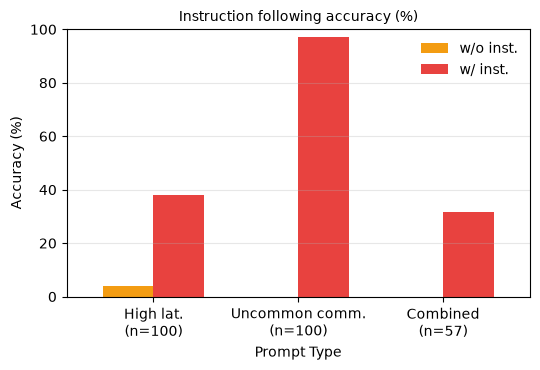

In [12]:
import matplotlib.pyplot as plt

ordem_tipos = ["High lat.", "Uncommon comm.", "Combined"]
tab = (df_ex3.pivot_table(index="tipo", columns="condicao", values="obedeceu", aggfunc="mean") * 100
       ).reindex(ordem_tipos)[["w/o inst.", "w/ inst."]]
n_por_tipo = df_ex3[df_ex3.condicao == "w/ inst."].groupby("tipo").size().reindex(ordem_tipos)

ax = tab.plot(kind="bar", figsize=(5.5, 3.8), rot=0, width=0.7, color=["#f39c12", "#e8423f"])
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in n_por_tipo.items()])
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Prompt Type")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
ax.set_title("Instruction following accuracy (%)", fontsize=10)
plt.tight_layout()
plt.show()

### Perguntas — Exercício 3

**(a) Sobre o paper.** Por que testar instruções **combinadas, nunca vistas
juntas no treino** é uma forma mais rigorosa de avaliar instruction-following
do que só testar cada instrução isolada?

> **Resposta:**

**(b) Sobre o exercício.** No gráfico de vocês, o resultado de *Combined*
mostra que o modelo consegue atender as duas instruções ao mesmo tempo,
mesmo nunca tendo visto essa combinação no treino?

> **Resposta:**

---
## Conclusão e limitações deste notebook

- **Exercícios 1 e 2** seguem o protocolo do paper (mesma métrica de
  *accuracy*, greedy vs. temperatura, mesmos 3 formatos, mesmas prompts de
  avaliação do repo) — em escala reduzida (dezenas de grafos por ponto, contra
  50 por combinação no paper), então esperem mais oscilação entre pontos.
- **Exercício 3** segue a ideia da Seção 4.4 / Figura 6 com as instruções reais
  do repo; a diferença é o limite de "latência alta" por serviço, aproximado pela
  maior latência observada nos prompts de avaliação (o paper usa o p90 dos
  dados brutos da Alibaba) — também em escala reduzida: 100 prompts por tipo
  (57 em *Combined*), contra até 1K no paper.
- O adapter `recursive+instruction` é usado empilhado sobre o `recursive`
  (ver introdução); os resultados podem diferir um pouco dos do paper também
  por usarmos o modelo em 4-bit e `transformers` em vez de vLLM.
- Nenhum desses exercícios treina nada — são o Llama-2-7B + os adapters LoRA
  publicados pelos autores.
- Os resultados ficam salvos em `resultados/ex1.csv`, `ex2.csv` e `ex3.csv`; o texto
  gerado em cada camada fica em `resultados/ex1_textos.jsonl` e `ex2_textos.jsonl`
  (e na coluna `saida` do `ex3.csv`), para inspecionar acertos e erros.